# Junction detections and sensors
Run the cells in order. Change `junction_id` to explore another junction.
Each row counts as a detection record, including repeated request updates.
The plot includes all source types. The sensor list includes `SENSOR` and `REMOTE_SENSOR` only.

Sensor names are inferred from the observed ID pattern: keep the location and direction, then remove the numeric detection suffix and everything after it. For example, `REMOTE_SENSOR-bridge.high_14-fc_du_161.riverside_w820439` becomes `REMOTE_SENSOR-bridge.high_14-fc_du_161.riverside_w`. Keep numbers inside location names, such as `161` and `_14`.
This groups IDs by their stable prefix; physical sensor identities would require producer documentation.

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = "2026-09-01.parquet"
junction_id = "bridge.corbins_12"

junction = pd.read_parquet(
    file_path,
    columns=["timestamp", "intersection_id", "sourceId", "source", "entryZone"],
    filters=[("intersection_id", "==", junction_id)],
)
junction["timestamp"] = pd.to_datetime(junction["timestamp"])
print(f"Detection records at {junction_id}: {len(junction):,}")

Detection records at bridge.corbins_12: 84,371


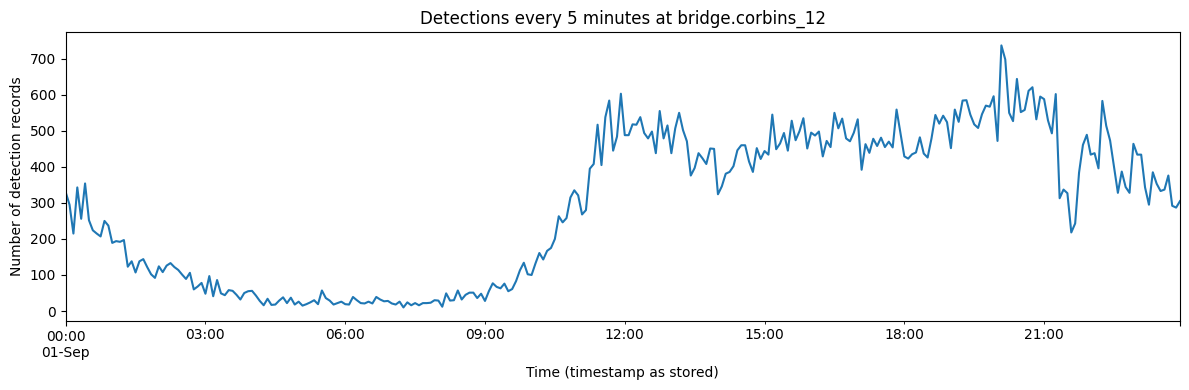

In [32]:
# Line plot for the junction selected above.
if junction.empty:
    print("No records found. Check junction_id.")
else:
    junction.set_index("timestamp").resample("5min").size().plot(
        kind="line", figsize=(12, 4)
    )
    plt.title(f"Detections every 5 minutes at {junction_id}")
    plt.xlabel("Time (timestamp as stored)")
    plt.ylabel("Number of detection records")
    plt.tight_layout()
    plt.show()

In [33]:
# Keep the original sourceId and add a cleaned sensor_id column.
# Examples: ..._se1978-3913069 -> ..._se; ..._nw8721-w01-0 -> ..._nw.
is_sensor = junction["source"].isin(["SENSOR"])
pattern = r"^((?:REMOTE_)?SENSOR-.*_(?:ne|nw|se|sw|n|e|s|w))\d+.*$"

junction["sensor_id"] = junction["sourceId"].where(is_sensor).str.replace(
    pattern, r"\1", regex=True
)

# Show a few original IDs beside their cleaned names.
examples = junction.loc[is_sensor, ["sourceId", "sensor_id"]].drop_duplicates("sensor_id")
print(examples.to_string(index=False))

# Unexpected formats remain unchanged so they can be inspected.
unmatched = junction.loc[
    is_sensor & junction["sourceId"].notna()
    & ~junction["sourceId"].str.match(pattern, na=False), "sourceId"
].unique()
if len(unmatched):
    print("IDs with an unexpected format (left unchanged):", unmatched)


                                                           sourceId                                              sensor_id
SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw16553-3913055 SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw
      SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw30122-3913076       SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw
        SENSOR-bridge.frantz_9-fc_du_bridge.frantz_se357227-3912872          SENSOR-bridge.frantz_9-fc_du_bridge.frantz_se
      SENSOR-bridge.corbins_12-fc_du_bridge.corbins_se32630-3913197       SENSOR-bridge.corbins_12-fc_du_bridge.corbins_se
          SENSOR-bridge.frantz_9-fc_du_bridge.frantz_ne3864-3913002          SENSOR-bridge.frantz_9-fc_du_bridge.frantz_ne
SENSOR-bridge.highschool_13-fc_du_bridge.highschool_sw60156-3914160 SENSOR-bridge.highschool_13-fc_du_bridge.highschool_sw
      SENSOR-bridge.corbins_12-fc_du_bridge.corbins_sw44039-3916661       SENSOR-bridge.corbins_12-fc_du_bridge.corbins_sw


In [34]:
# List all cleaned sensor names and their detection-record counts.
sensor_counts = junction["sensor_id"].value_counts().rename_axis("sensor_id")
print(f"{len(sensor_counts)} sensor groups recorded at {junction_id}:")
print(sensor_counts.to_string(name="detection_records"))

# These source types are not included in the sensor list.
print("\nOther source types:")
print(junction.loc[~is_sensor, "source"].value_counts().to_string())


7 sensor groups recorded at bridge.corbins_12:
sensor_id
SENSOR-bridge.corbins_12-fc_du_bridge.corbins_nw          21950
SENSOR-bridge.highschool_13-fc_du_bridge.highschool_nw    20266
SENSOR-bridge.corbins_12-fc_du_bridge.corbins_se          19859
SENSOR-bridge.frantz_9-fc_du_bridge.frantz_se             16039
SENSOR-bridge.corbins_12-fc_du_bridge.corbins_sw           3358
SENSOR-bridge.frantz_9-fc_du_bridge.frantz_ne              1700
SENSOR-bridge.highschool_13-fc_du_bridge.highschool_sw      304
Name: count

Other source types:
source
STARVATION    746
NTCIP_CALL    149


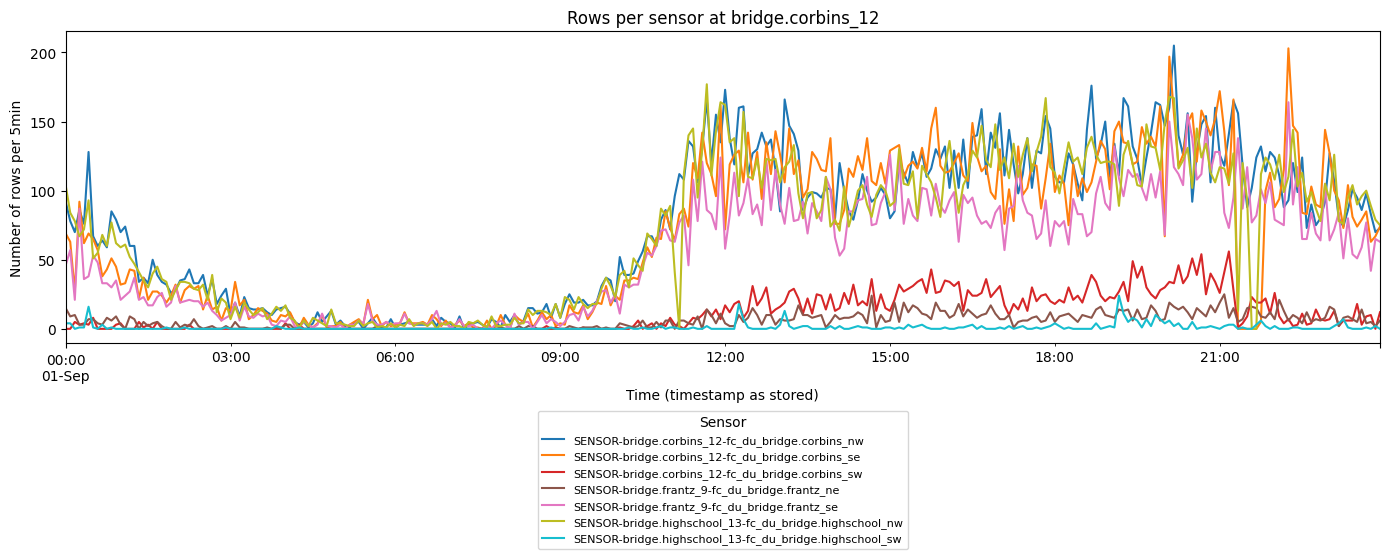

In [35]:
# Count rows over time for each cleaned sensor ID.
interval = "5min"  # Change to "1min" or "1h" if needed.
sensor_rows = junction.dropna(subset=["sensor_id", "timestamp"])

if sensor_rows.empty:
    print("No sensor records to plot.")
else:
    rows_over_time = (
        sensor_rows.groupby([pd.Grouper(key="timestamp", freq=interval), "sensor_id"])
        .size()
        .unstack("sensor_id", fill_value=0)
    )
    # Include intervals with no records for any sensor.
    time_index = pd.date_range(
        junction["timestamp"].min().floor(interval),
        junction["timestamp"].max().floor(interval),
        freq=interval,
    )
    rows_over_time = rows_over_time.reindex(time_index, fill_value=0)

    rows_over_time.plot(kind="line", figsize=(14, 6), colormap="tab10")
    plt.title(f"Rows per sensor at {junction_id}")
    plt.xlabel("Time (timestamp as stored)")
    plt.ylabel(f"Number of rows per {interval}")
    plt.legend(title="Sensor", bbox_to_anchor=(0.5, -0.2), loc="upper center", fontsize=8)
    plt.tight_layout()
    plt.show()


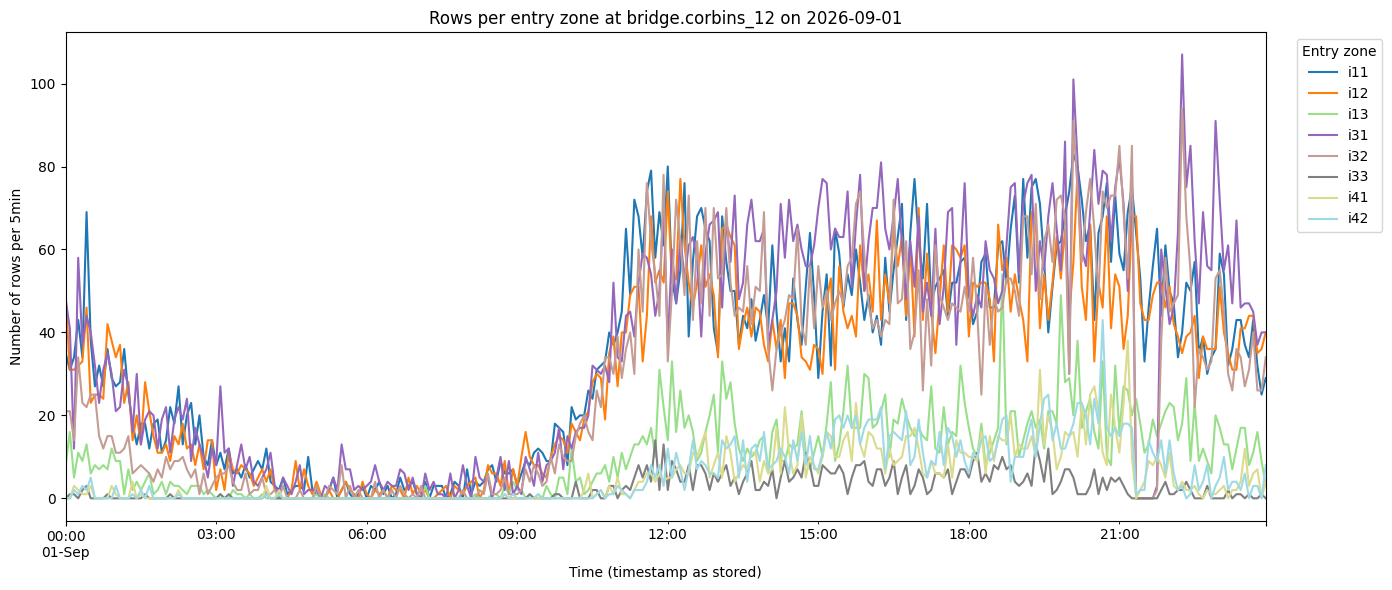

In [37]:
# Compare entry zones for one day at the selected junction.
selected_day = "2026-09-01"
interval = "5min"  # Change to "1min" or "1h" if needed.

start = pd.Timestamp(selected_day)
end = start + pd.Timedelta(days=1)
day_rows = junction[(junction["timestamp"] >= start) & (junction["timestamp"] < end)].copy()

# Missing zones are shown separately so their records are not lost.
# day_rows["entryZone"] = day_rows["entryZone"].fillna("Unknown zone")

if day_rows.empty:
    print("No records for this junction and day.")
else:
    zone_counts = (
        day_rows.groupby([pd.Grouper(key="timestamp", freq=interval), "entryZone"])
        .size()
        .unstack("entryZone", fill_value=0)
    )
    time_index = pd.date_range(start, end, freq=interval, inclusive="left")
    zone_counts = zone_counts.reindex(time_index, fill_value=0)

    zone_counts.plot(kind="line", figsize=(14, 6), colormap="tab20")
    plt.title(f"Rows per entry zone at {junction_id} on {selected_day}")
    plt.xlabel("Time (timestamp as stored)")
    plt.ylabel(f"Number of rows per {interval}")
    plt.legend(title="Entry zone", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
